In [1]:
import numpy as np
import pandas as pd
from numbers import Number
from IPython.display import display
import matplotlib.pyplot as plt
import re

In [2]:
# Data import and cleaning from previous milestone
base_url = "https://huggingface.co/datasets/google-research-datasets/go_emotions/resolve/main/simplified/"

train_df = pd.read_parquet(base_url + "train-00000-of-00001.parquet")
val_df = pd.read_parquet(base_url + "validation-00000-of-00001.parquet")
test_df = pd.read_parquet(base_url + "test-00000-of-00001.parquet")

# Label and group mappings
LABEL_NAMES = [
    "admiration","amusement","anger","annoyance","approval","caring",
    "confusion","curiosity","desire","disappointment","disapproval",
    "disgust","embarrassment","excitement","fear","gratitude","grief",
    "joy","love","nervousness","optimism","pride","realization","relief",
    "remorse","sadness","surprise","neutral"
]
# Map each label to its corresponding group
GROUP_MAP = {
    "admiration":"positive","amusement":"positive","approval":"positive",
    "caring":"positive","desire":"positive","excitement":"positive",
    "gratitude":"positive","joy":"positive","love":"positive",
    "optimism":"positive","pride":"positive","relief":"positive",
    "anger":"negative","annoyance":"negative","disappointment":"negative",
    "disapproval":"negative","disgust":"negative","embarrassment":"negative",
    "fear":"negative","grief":"negative","nervousness":"negative",
    "remorse":"negative","sadness":"negative",
    "confusion":"ambiguous","curiosity":"ambiguous",
    "realization":"ambiguous","surprise":"ambiguous",
    "neutral":"neutral"
}
# Function to convert label IDs to their corresponding groups
def labels_to_groups_all(label_ids):
    names = [LABEL_NAMES[i] for i in label_ids]
    groups = [GROUP_MAP[n] for n in names]
    return list(dict.fromkeys(groups))

# Process each dataset split
def process_split(df):
    df = df.copy()
    df["all_groups"] = df["labels"].apply(labels_to_groups_all)
    df["num_distinct_groups"] = df["all_groups"].apply(len)
    clean = df[df["num_distinct_groups"] == 1].copy()
    clean["group_label"] = clean["all_groups"].apply(lambda g: g[0])
    conflict = df[df["num_distinct_groups"] > 1].copy()
    return clean, conflict

# Process all dataset splits
train_clean, train_conflict = process_split(train_df)
val_clean, val_conflict = process_split(val_df)
test_clean, test_conflict = process_split(test_df)

def clean_text(text):
    text = re.sub(r"\[NAME\]|\[RELIGION\]", "", text) #remove hidden placeholder words
    text = re.sub(r"http\S+", "", text)               #remove links
    text = re.sub(r"\s+", " ", text).strip()          #remove extra whitespace
    return text

train_clean["clean_text"] = train_clean["text"].apply(clean_text)
val_clean["clean_text"] = val_clean["text"].apply(clean_text)
test_clean["clean_text"] = test_clean["text"].apply(clean_text)

train_clean = train_clean[train_clean["clean_text"].str.strip() != ""]
val_clean = val_clean[val_clean["clean_text"].str.strip() != ""]
test_clean = test_clean[test_clean["clean_text"].str.strip() != ""]

# Remove duplicate text entries shared across splits to prevent data leakage
leak_texts = set(val_clean["clean_text"]) | set(test_clean["clean_text"])
train_clean = train_clean[~train_clean["clean_text"].isin(leak_texts)]


In [3]:
# Making a naive majority class predition benchmark
import time
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_score

naive_majority_classifier = DummyClassifier(strategy="most_frequent", random_state=42)

# Measure training runtime
t0 = time.perf_counter()
naive_majority_classifier.fit(train_clean["clean_text"], train_clean["group_label"])
naive_train_time_ms = (time.perf_counter() - t0) * 1000

# The naive majority classifier should just guess "positive" as the group label for every prediction

# Validation predictions evaluated on val_clean to protect the test set
t0 = time.perf_counter()
naive_val_preds = naive_majority_classifier.predict(val_clean["clean_text"])
naive_infer_time_ms = (time.perf_counter() - t0) * 1000
predictions = naive_val_preds

# Compute required metrics on val_clean
naive_val_f1 = f1_score(val_clean["group_label"], naive_val_preds, average="macro", zero_division=0)
naive_val_prec = precision_score(val_clean["group_label"], naive_val_preds, average="macro", zero_division=0)
naive_val_rec = recall_score(val_clean["group_label"], naive_val_preds, average="macro", zero_division=0)
naive_val_acc = accuracy_score(val_clean["group_label"], naive_val_preds)
accuracy = naive_val_acc

# Variables prepared for the Baseline Comparison Table
naive_eval_split = f"GoEmotions Validation Set (n={len(val_clean)})"
naive_time_str = f"{naive_train_time_ms:.2f} / {naive_infer_time_ms:.2f}"

print(f"Predictions: {predictions}")
print(f"Validation Accuracy: {naive_val_acc:.4f}")
print(f"Validation Macro F1 (Primary): {naive_val_f1:.4f}")
print(f"Validation Macro Precision: {naive_val_prec:.4f}")
print(f"Validation Macro Recall: {naive_val_rec:.4f}")
print(f"Training Time: {naive_train_time_ms:.2f} ms")
print(f"Inference Time: {naive_infer_time_ms:.2f} ms")


Predictions: ['positive' 'positive' 'positive' ... 'positive' 'positive' 'positive']
Validation Accuracy: 0.3878
Validation Macro F1 (Primary): 0.1397
Validation Macro Precision: 0.0970
Validation Macro Recall: 0.2500
Training Time: 64.62 ms
Inference Time: 5.66 ms


In [4]:
# Naive Bayes

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

In [5]:



def evaluate(name, model, X_tr, y_tr, X_va, y_va, X_te, y_te):
    t0 = time.time()
    model.fit(X_tr, y_tr)
    train_time = time.time() - t0
    return {
        "Model": name,
        "Train macro-F1": f1_score(y_tr, model.predict(X_tr), average="macro"),
        "Val macro-F1":   f1_score(y_va, model.predict(X_va), average="macro"),
        "Test macro-F1":  f1_score(y_te, model.predict(X_te), average="macro"),
        "Train time (s)": round(train_time, 2),
    }

In [6]:
# Multinomial Naive Bayes
import time
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

classify_nb = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("nb", MultinomialNB(alpha=1.0))
])

# Measure training runtime
t0 = time.perf_counter()
classify_nb.fit(train_clean["clean_text"], train_clean["group_label"])
nb_train_time_ms = (time.perf_counter() - t0) * 1000

# Validation predictions evaluated on val_clean to protect the test set
t0 = time.perf_counter()
nb_val_preds = classify_nb.predict(val_clean["clean_text"])
nb_infer_time_ms = (time.perf_counter() - t0) * 1000
predictions = nb_val_preds

# Compute required metrics on val_clean
nb_val_f1 = f1_score(val_clean["group_label"], nb_val_preds, average="macro", zero_division=0)
nb_val_prec = precision_score(val_clean["group_label"], nb_val_preds, average="macro", zero_division=0)
nb_val_rec = recall_score(val_clean["group_label"], nb_val_preds, average="macro", zero_division=0)
nb_val_acc = accuracy_score(val_clean["group_label"], nb_val_preds)
accuracy = nb_val_acc

# Key settings / notes for baseline table
nb_settings_notes = "TF-IDF (ngram_range=(1, 2)), MultinomialNB(alpha=1.0)"

# Training and inference time string for baseline table
nb_time = f"{nb_train_time_ms:.2f} / {nb_infer_time_ms:.2f}"

# Print predictions and metrics
print(f"Predictions: {predictions}")
print(f"Validation Accuracy: {nb_val_acc:.4f}")
print(f"Validation Macro F1 (Primary): {nb_val_f1:.4f}")
print(f"Validation Macro Precision: {nb_val_prec:.4f}")
print(f"Validation Macro Recall: {nb_val_rec:.4f}")
print(f"Training Time: {nb_train_time_ms:.2f} ms")
print(f"Inference Time: {nb_infer_time_ms:.2f} ms")


Predictions: ['positive' 'positive' 'neutral' ... 'neutral' 'neutral' 'positive']
Validation Accuracy: 0.5079
Validation Macro F1 (Primary): 0.3173
Validation Macro Precision: 0.7107
Validation Macro Recall: 0.3571
Training Time: 5161.22 ms
Inference Time: 329.95 ms


In [7]:
# BASELINE COMPARISON TABLE
import pandas as pd

# Comparison table
baseline_table_data = [
    {
        "Model / Baseline Tier": "Naive Benchmark (DummyClassifier: most_frequent)",
        "Evaluation Split": naive_eval_split,
        "Macro F1 (Primary)": round(naive_val_f1, 4),
        "Macro Precision": round(naive_val_prec, 4),
        "Macro Recall": round(naive_val_rec, 4),
        "Accuracy": round(naive_val_acc, 4),
        "Train / Infer Time (ms)": naive_time_str,
        "Key Settings / Notes": "strategy='most_frequent', random_state=42 (always predicts 'positive')"
    },
    {
        "Model / Baseline Tier": "Course Baseline (Naive Bayes)",
        "Evaluation Split": f"GoEmotions Validation Set (n={len(val_clean)})",
        "Macro F1 (Primary)": round(nb_val_f1, 4),
        "Macro Precision": round(nb_val_prec, 4),
        "Macro Recall": round(nb_val_rec, 4),
        "Accuracy": round(nb_val_acc, 4),
        "Train / Infer Time (ms)": nb_time,
        "Key Settings / Notes": nb_settings_notes
    },
    {
        "Model / Baseline Tier": "Reference: BERT-base (Demszky et al., 2020)",
        "Evaluation Split": "GoEmotions Test (n=5,427)",
        "Macro F1 (Primary)": 0.69,
        "Macro Precision": 0.65,
        "Macro Recall": 0.74,
        "Accuracy": "N/A",
        "Train / Infer Time (ms)": "N/A",
        "Key Settings / Notes": "BERT-base baseline values from Demszky et al. (2020, Table 5)"
    }
]

baseline_comparison_df = pd.DataFrame(baseline_table_data)

# Table formatting
pd.set_option("display.max_colwidth", None)
metric_columns = [
    "Macro F1 (Primary)",
    "Macro Precision",
    "Macro Recall",
    "Accuracy",
]
numeric_formatters = {
    column: lambda value: f"{value:g}" if isinstance(value, Number) else value
    for column in metric_columns
}
baseline_comparison_style = (
    baseline_comparison_df.style
    .format(numeric_formatters)
    .set_properties(**{
        "white-space": "normal",
        "overflow-wrap": "anywhere",
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [("white-space", "normal"), ("overflow-wrap", "anywhere")],
        },
        {
            "selector": "td",
            "props": [("white-space", "normal"), ("overflow-wrap", "anywhere")],
        },
        {
            "selector": "table",
            "props": [("table-layout", "auto"), ("width", "100%")],
        },
    ])
)
display(baseline_comparison_style)


,Model / Baseline Tier,Evaluation Split,Macro F1 (Primary),Macro Precision,Macro Recall,Accuracy,Train / Infer Time (ms),Key Settings / Notes
0,Naive Benchmark (DummyClassifier: most_frequent),GoEmotions Validation Set (n=5005),0.1397,0.097,0.25,0.3878,64.62 / 5.66,"strategy='most_frequent', random_state=42 (always predicts 'positive')"
1,Course Baseline (Naive Bayes),GoEmotions Validation Set (n=5005),0.3173,0.7107,0.3571,0.5079,5161.22 / 329.95,"TF-IDF (ngram_range=(1, 2)), MultinomialNB(alpha=1.0)"
2,"Reference: BERT-base (Demszky et al., 2020)","GoEmotions Test (n=5,427)",0.69,0.65,0.74,N/A,N/A,"BERT-base baseline values from Demszky et al. (2020, Table 5)"


In [8]:
from google.colab import drive
drive.mount('/content/drive')

import os

SAVE_DIR = "/content/drive/MyDrive/ML_Checkpoints"
os.makedirs(SAVE_DIR, exist_ok=True)

Mounted at /content/drive


In [9]:

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sentence_transformers import SentenceTransformer  # pip install sentence-transformers

SEED = 42
X_tr, y_tr = train_clean["clean_text"], train_clean["group_label"]
X_va, y_va = val_clean["clean_text"],   val_clean["group_label"]
X_te, y_te = test_clean["clean_text"],  test_clean["group_label"]

# ---------- bootstrap helpers ----------
def bootstrap_f1(y_true, y_pred, n=1000, seed=SEED):
    """Resample the test set to estimate uncertainty in macro-F1."""
    rng = np.random.default_rng(seed)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    scores = np.array([
        f1_score(y_true[i], y_pred[i], average="macro")
        for i in (rng.integers(0, len(y_true), len(y_true)) for _ in range(n))
    ])
    return scores.mean(), scores.std(), np.percentile(scores, [2.5, 97.5])

def paired_diff(y_true, pred_a, pred_b, n=1000, seed=SEED):
    """95% CI for (macro-F1 of A) - (macro-F1 of B) on the same resamples."""
    rng = np.random.default_rng(seed)
    y_true, pred_a, pred_b = map(np.asarray, (y_true, pred_a, pred_b))
    diffs = []
    for _ in range(n):
        i = rng.integers(0, len(y_true), len(y_true))
        diffs.append(f1_score(y_true[i], pred_a[i], average="macro")
                     - f1_score(y_true[i], pred_b[i], average="macro"))
    return np.percentile(diffs, [2.5, 97.5])  # if this excludes 0, the gap is meaningful

# ---------- features (fit on TRAIN only) ----------
tfidf = TfidfVectorizer(max_features=10000)
Xtr_t = tfidf.fit_transform(X_tr)
Xva_t = tfidf.transform(X_va)
Xte_t = tfidf.transform(X_te)

labse = SentenceTransformer("sentence-transformers/LaBSE")

t0 = time.time()

# Training embeddings
train_path = os.path.join(SAVE_DIR, "labse_train.npy")

if os.path.exists(train_path):
    Etr = np.load(train_path)
    print("Loaded training embeddings")
else:
    Etr = labse.encode(list(X_tr), batch_size=64, show_progress_bar=True)
    np.save(train_path, Etr)
    print("Saved training embeddings")

# Validation embeddings
val_path = os.path.join(SAVE_DIR, "labse_val.npy")

if os.path.exists(val_path):
    Eva = np.load(val_path)
    print("Loaded validation embeddings")
else:
    Eva = labse.encode(list(X_va), batch_size=64, show_progress_bar=True)
    np.save(val_path, Eva)
    print("Saved validation embeddings")

# Test embeddings
test_path = os.path.join(SAVE_DIR, "labse_test.npy")

if os.path.exists(test_path):
    Ete = np.load(test_path)
    print("Loaded test embeddings")
else:
    Ete = labse.encode(list(X_te), batch_size=64, show_progress_bar=True)
    np.save(test_path, Ete)
    print("Saved test embeddings")

embed_time = time.time() - t0

# ---------- run one model ----------
test_preds = {}  # kept for error analysis and paired comparisons

def run(name, model, Xtr, Xva, Xte, extra_time=0.0):
    t0 = time.time()
    model.fit(Xtr, y_tr)
    train_time = time.time() - t0 + extra_time
    p_tr, p_va, p_te = model.predict(Xtr), model.predict(Xva), model.predict(Xte)
    test_preds[name] = p_te
    mean, sd, (lo, hi) = bootstrap_f1(y_te, p_te)
    return {
        "Model": name,
        "Train macro-F1": round(f1_score(y_tr, p_tr, average="macro"), 4),
        "Val macro-F1":   round(f1_score(y_va, p_va, average="macro"), 4),
        "Test macro-F1":  round(f1_score(y_te, p_te, average="macro"), 4),
        "Test boot. mean ± sd": f"{mean:.4f} ± {sd:.4f}",
        "Test 95% CI": f"[{lo:.4f}, {hi:.4f}]",
        "Train time (s)": round(train_time, 2),
    }

import pickle

rows = []
test_preds = {}

models = [
    ("Naive benchmark (majority class)",
     DummyClassifier(strategy="most_frequent"), Xtr_t, Xva_t, Xte_t, 0.0),

    ("TF-IDF + Naive Bayes (baseline)",
     MultinomialNB(alpha=1.0), Xtr_t, Xva_t, Xte_t, 0.0),

    ("TF-IDF + Logistic Regression (intermediate)",
     LogisticRegression(max_iter=1000, random_state=SEED), Xtr_t, Xva_t, Xte_t, 0.0),

    ("LaBSE (frozen) + Logistic Regression (main)",
     LogisticRegression(max_iter=1000, random_state=SEED), Etr, Eva, Ete, embed_time)
]

for name, model, Xtr, Xva, Xte, extra_time in models:
    result = run(name, model, Xtr, Xva, Xte, extra_time)
    rows.append(result)

    # Save progress after every model
    results_df = pd.DataFrame(rows)
    results_df.to_csv(os.path.join(SAVE_DIR, "results.csv"), index=False)

    with open(os.path.join(SAVE_DIR, "predictions.pkl"), "wb") as f:
        pickle.dump(test_preds, f)

    print(f"Saved progress after: {name}")

display(results_df)

# ---------- are the differences meaningful? ----------
nb, lr, lb = (test_preds[k] for k in [
    "TF-IDF + Naive Bayes (baseline)",
    "TF-IDF + Logistic Regression (intermediate)",
    "LaBSE (frozen) + Logistic Regression (main)"])
print("LR - NB   95% CI:", paired_diff(y_te, lr, nb))
print("LaBSE - LR 95% CI:", paired_diff(y_te, lb, lr))

modules.json:   0%|          | 0.00/461 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/2.02k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/804 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.88GB            

... (9 outputs left out)

2_Dense/model.safetensors: downloading bytes:           |  0.00B            

Loaded training embeddings
Loaded validation embeddings
Loaded test embeddings
Saved progress after: Naive benchmark (majority class)
Saved progress after: TF-IDF + Naive Bayes (baseline)
Saved progress after: TF-IDF + Logistic Regression (intermediate)
Saved progress after: LaBSE (frozen) + Logistic Regression (main)


,Model,Train macro-F1,Val macro-F1,Test macro-F1,Test boot. mean ± sd,Test 95% CI,Train time (s)
0,Naive benchmark (majority class),0.1375,0.1397,0.1352,0.1353 ± 0.0018,"[0.1318, 0.1388]",0.02
1,TF-IDF + Naive Bayes (baseline),0.5151,0.4223,0.4238,0.4237 ± 0.0066,"[0.4111, 0.4365]",0.10
2,TF-IDF + Logistic Regression (intermediate),0.6775,0.5796,0.5836,0.5835 ± 0.0082,"[0.5670, 0.5997]",6.90
3,LaBSE (frozen) + Logistic Regression (main),0.6390,0.6181,0.6282,0.6280 ± 0.0078,"[0.6136, 0.6437]",28.86


LR - NB   95% CI: [0.14383252 0.1750433 ]
LaBSE - LR 95% CI: [0.02670492 0.06164883]


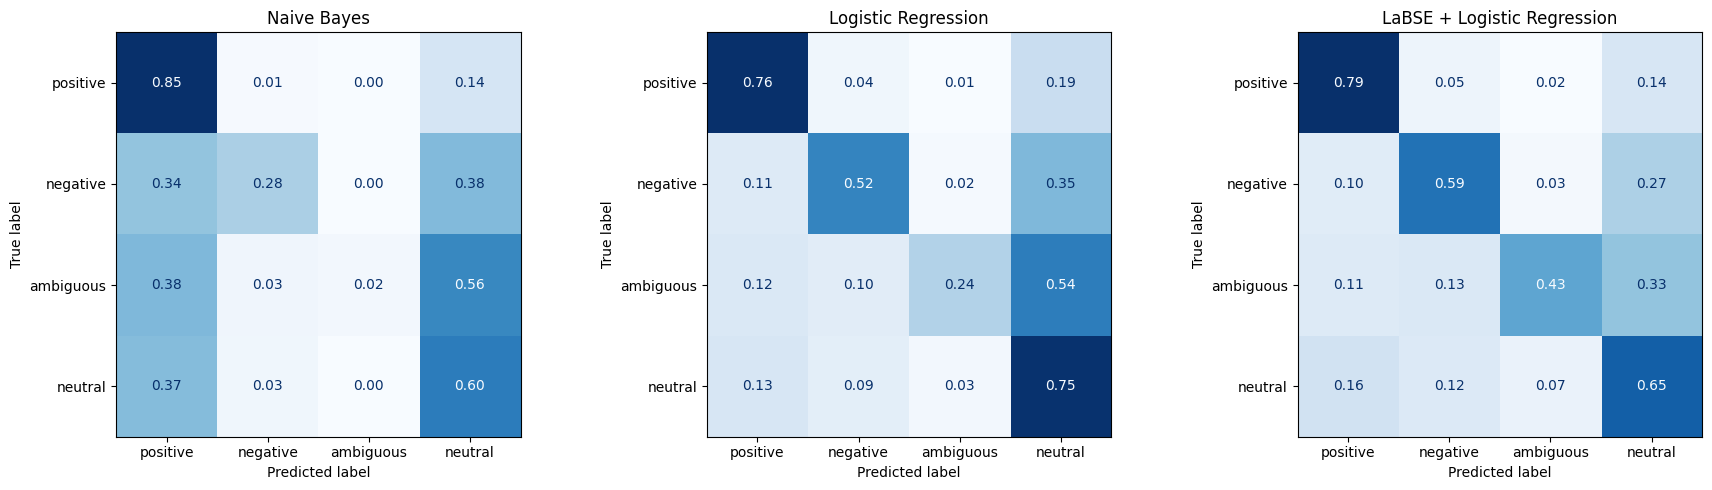

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

LABELS = ["positive", "negative", "ambiguous", "neutral"]

models_to_plot = [
    ("Naive Bayes",         "TF-IDF + Naive Bayes (baseline)"),
    ("Logistic Regression", "TF-IDF + Logistic Regression (intermediate)"),
    ("LaBSE + Logistic Regression", "LaBSE (frozen) + Logistic Regression (main)"),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (title, key) in zip(axes, models_to_plot):
    ConfusionMatrixDisplay.from_predictions(
        y_te, test_preds[key], labels=LABELS,
        normalize="true", values_format=".2f", cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.savefig("fig1_confusion_matrices.png", dpi=200)
plt.show()

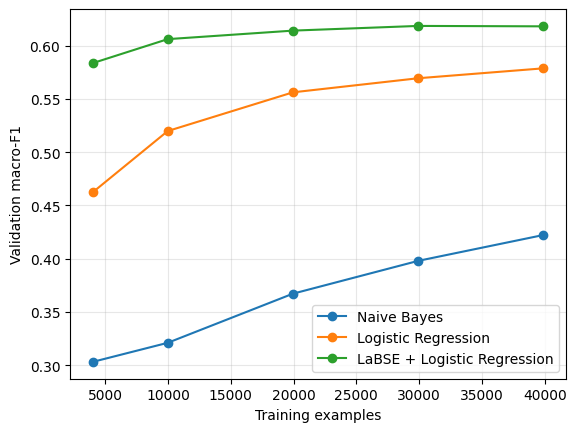

{'Naive Bayes': [0.303, 0.321, 0.367, 0.398, 0.422], 'Logistic Regression': [0.462, 0.52, 0.556, 0.569, 0.579], 'LaBSE + Logistic Regression': [0.584, 0.606, 0.614, 0.618, 0.618]}


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

CKPT = "/content/drive/MyDrive/ML_Checkpoints"

Etr = np.load(f"{CKPT}/labse_train.npy")
Eva = np.load(f"{CKPT}/labse_val.npy")
Ete = np.load(f"{CKPT}/labse_test.npy")

fractions = [0.1, 0.25, 0.5, 0.75, 1.0]
rng = np.random.default_rng(42)
results = {"Naive Bayes": [], "Logistic Regression": [], "LaBSE + Logistic Regression": []}

for frac in fractions:
    idx = rng.choice(len(X_tr), int(frac * len(X_tr)), replace=False)
    ys = y_tr.iloc[idx]

    # TF-IDF models: refit the vectorizer on the subset only
    Xs = X_tr.iloc[idx]
    vec = TfidfVectorizer(max_features=10000)
    Xs_t, Xv_t = vec.fit_transform(Xs), vec.transform(X_va)
    for name, model in [("Naive Bayes", MultinomialNB(alpha=1.0)),
                        ("Logistic Regression", LogisticRegression(max_iter=1000, random_state=42))]:
        model.fit(Xs_t, ys)
        results[name].append(f1_score(y_va, model.predict(Xv_t), average="macro"))

    # LaBSE: same rows from the saved embeddings
    lb = LogisticRegression(max_iter=1000, random_state=42).fit(Etr[idx], ys)
    results["LaBSE + Logistic Regression"].append(
        f1_score(y_va, lb.predict(Eva), average="macro"))

for name, scores in results.items():
    plt.plot([f * len(X_tr) for f in fractions], scores, marker="o", label=name)
plt.xlabel("Training examples")
plt.ylabel("Validation macro-F1")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("fig2_learning_curve.png", dpi=200)
plt.show()

print({k: [round(s, 3) for s in v] for k, v in results.items()})

In [12]:
from sklearn.metrics import classification_report

for key in ["TF-IDF + Naive Bayes (baseline)",
            "TF-IDF + Logistic Regression (intermediate)"]:
    print(key)
    print(classification_report(y_te, test_preds[key], digits=3))

TF-IDF + Naive Bayes (baseline)
              precision    recall  f1-score   support

   ambiguous      0.917     0.023     0.044       488
    negative      0.781     0.283     0.416      1070
     neutral      0.504     0.598     0.547      1606
    positive      0.580     0.847     0.689      1863

    accuracy                          0.568      5027
   macro avg      0.695     0.438     0.424      5027
weighted avg      0.631     0.568     0.523      5027

TF-IDF + Logistic Regression (intermediate)
              precision    recall  f1-score   support

   ambiguous      0.546     0.244     0.337       488
    negative      0.681     0.518     0.588      1070
     neutral      0.551     0.752     0.636      1606
    positive      0.786     0.761     0.773      1863

    accuracy                          0.656      5027
   macro avg      0.641     0.569     0.584      5027
weighted avg      0.665     0.656     0.648      5027



In [13]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

# --- Naive benchmark: add macro-F1 ---
naive_preds = naive_majority_classifier.predict(test_clean["clean_text"])
naive_accuracy = accuracy_score(test_clean["group_label"], naive_preds)
naive_f1 = f1_score(test_clean["group_label"], naive_preds, average="macro")

print(f"Naive benchmark — Accuracy: {naive_accuracy:.4f}, Macro-F1: {naive_f1:.4f}")

# --- Course-level baseline: TF-IDF + Naive Bayes ---
vectorizer = TfidfVectorizer(max_features=10000)
X_train_vec = vectorizer.fit_transform(train_clean["clean_text"])
X_test_vec = vectorizer.transform(test_clean["clean_text"])

nb_classifier = MultinomialNB()
nb_classifier.fit(X_train_vec, train_clean["group_label"])
nb_preds = nb_classifier.predict(X_test_vec)

nb_accuracy = accuracy_score(test_clean["group_label"], nb_preds)
nb_f1 = f1_score(test_clean["group_label"], nb_preds, average="macro")

print(f"Naive Bayes — Accuracy: {nb_accuracy:.4f}, Macro-F1: {nb_f1:.4f}")
print(classification_report(test_clean["group_label"], nb_preds))

cm = confusion_matrix(test_clean["group_label"], nb_preds,
                       labels=["positive","negative","ambiguous","neutral"])
print(cm)

Naive benchmark — Accuracy: 0.3706, Macro-F1: 0.1352
Naive Bayes — Accuracy: 0.5675, Macro-F1: 0.4238
              precision    recall  f1-score   support

   ambiguous       0.92      0.02      0.04       488
    negative       0.78      0.28      0.42      1070
     neutral       0.50      0.60      0.55      1606
    positive       0.58      0.85      0.69      1863

    accuracy                           0.57      5027
   macro avg       0.70      0.44      0.42      5027
weighted avg       0.63      0.57      0.52      5027

[[1578   15    0  270]
 [ 364  303    0  403]
 [ 186   17   11  274]
 [ 591   53    1  961]]


In [15]:




Etr = np.load(f"{CKPT}/labse_train.npy")
Eva = np.load(f"{CKPT}/labse_val.npy")
Ete = np.load(f"{CKPT}/labse_test.npy")
assert len(Etr) == len(X_tr) and len(Eva) == len(X_va) and len(Ete) == len(X_te)

log = []  # experiment log: every configuration tried

def tune(name, make_model, grid, Xtr, Xva):
    best = None
    for params in grid:
        t0 = time.time()
        m = make_model(**params).fit(Xtr, y_tr)
        val_f1 = f1_score(y_va, m.predict(Xva), average="macro")
        log.append({"model": name, **params,
                    "val_macro_f1": round(val_f1, 4),
                    "fit_seconds": round(time.time() - t0, 2)})
        if best is None or val_f1 > best[0]:
            best = (val_f1, params)
    return best[1]

make_lr = lambda C: LogisticRegression(C=C, max_iter=1000, random_state=SEED)
nb_grid = [{"alpha": a} for a in [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]]
lr_grid = [{"C": c} for c in [0.03, 0.1, 0.3, 1, 3, 10]]

best_nb    = tune("TF-IDF + Naive Bayes",       lambda alpha: MultinomialNB(alpha=alpha), nb_grid, Xtr_t, Xva_t)
best_lr    = tune("TF-IDF + Logistic Regression", make_lr, lr_grid, Xtr_t, Xva_t)
best_labse = tune("LaBSE + Logistic Regression",  make_lr, lr_grid, Etr,   Eva)

print(best_nb, best_lr, best_labse)
pd.DataFrame(log).to_csv("experiment_log.csv", index=False)
display(pd.DataFrame(log))

{'alpha': 0.03} {'C': 3} {'C': 3}


,model,alpha,val_macro_f1,fit_seconds,C
0,TF-IDF + Naive Bayes,0.01,0.4523,0.26,NaN
1,TF-IDF + Naive Bayes,0.03,0.4528,0.21,NaN
2,TF-IDF + Naive Bayes,0.10,0.4493,0.31,NaN
3,TF-IDF + Naive Bayes,0.30,0.4457,0.34,NaN
4,TF-IDF + Naive Bayes,1.00,0.4223,0.30,NaN
5,TF-IDF + Naive Bayes,3.00,0.3584,0.30,NaN
6,TF-IDF + Logistic Regression,NaN,0.3950,3.90,0.03
7,TF-IDF + Logistic Regression,NaN,0.4889,8.88,0.10
8,TF-IDF + Logistic Regression,NaN,0.5515,12.99,0.30
9,TF-IDF + Logistic Regression,NaN,0.5796,20.21,1.00


In [16]:
configs = {
    "Naive benchmark (majority class)": (DummyClassifier(strategy="most_frequent"), Xtr_t, Xva_t, Xte_t, "-"),
    "TF-IDF + Naive Bayes":             (MultinomialNB(**best_nb), Xtr_t, Xva_t, Xte_t, best_nb),
    "TF-IDF + Logistic Regression":     (make_lr(**best_lr), Xtr_t, Xva_t, Xte_t, best_lr),
    "LaBSE + Logistic Regression":      (make_lr(**best_labse), Etr, Eva, Ete, best_labse),
}

test_preds, rows = {}, []
for name, (model, Xtr, Xva, Xte, params) in configs.items():
    t0 = time.time(); model.fit(Xtr, y_tr); fit_s = time.time() - t0
    p_va, p_te = model.predict(Xva), model.predict(Xte)
    test_preds[name] = p_te
    mean, sd, (lo, hi) = bootstrap_f1(y_te, p_te)
    amb = f1_score(y_te, p_te, labels=["ambiguous"], average=None)[0]
    rows.append({
        "Model": name, "Tuned setting": params,
        "Val macro-F1": round(f1_score(y_va, p_va, average="macro"), 4),
        "Test macro-F1": round(f1_score(y_te, p_te, average="macro"), 4),
        "Test 95% CI": f"[{lo:.3f}, {hi:.3f}]",
        "Macro precision": round(precision_score(y_te, p_te, average="macro", zero_division=0), 4),
        "Macro recall": round(recall_score(y_te, p_te, average="macro", zero_division=0), 4),
        "Accuracy": round(accuracy_score(y_te, p_te), 4),
        "Ambiguous F1": round(amb, 4),
        "Fit time (s)": round(fit_s, 2),
    })

main_table = pd.DataFrame(rows)
main_table.to_csv("main_results_table.csv", index=False)
display(main_table)

print("LR - NB   :", paired_diff(y_te, test_preds["TF-IDF + Logistic Regression"], test_preds["TF-IDF + Naive Bayes"]))
print("LaBSE - LR:", paired_diff(y_te, test_preds["LaBSE + Logistic Regression"], test_preds["TF-IDF + Logistic Regression"]))

,Model,Tuned setting,Val macro-F1,Test macro-F1,Test 95% CI,Macro precision,Macro recall,Accuracy,Ambiguous F1,Fit time (s)
0,Naive benchmark (majority class),-,0.1397,0.1352,"[0.132, 0.139]",0.0926,0.2500,0.3706,0.0000,0.02
1,TF-IDF + Naive Bayes,{'alpha': 0.03},0.4528,0.4674,"[0.452, 0.483]",0.5850,0.4623,0.5665,0.1722,0.09
2,TF-IDF + Logistic Regression,{'C': 3},0.5849,0.5893,"[0.573, 0.606]",0.6276,0.5753,0.6517,0.3752,7.82
3,LaBSE + Logistic Regression,{'C': 3},0.6229,0.6342,"[0.618, 0.648]",0.6468,0.6252,0.6748,0.4994,34.60


LR - NB   : [0.10639052 0.13841934]
LaBSE - LR: [0.0271799  0.06159322]


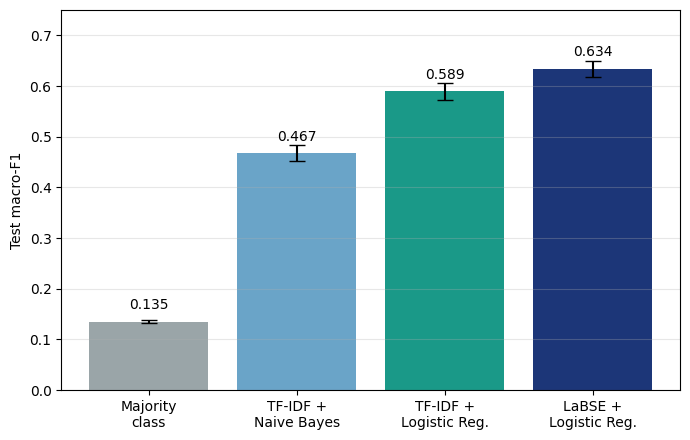

In [17]:


names = ["Naive benchmark (majority class)", "TF-IDF + Naive Bayes",
         "TF-IDF + Logistic Regression", "LaBSE + Logistic Regression"]
labels = ["Majority\nclass", "TF-IDF +\nNaive Bayes", "TF-IDF +\nLogistic Reg.", "LaBSE +\nLogistic Reg."]

pts, lows, highs = [], [], []
for n in names:
    p = f1_score(y_te, test_preds[n], average="macro")
    _, _, (lo, hi) = bootstrap_f1(y_te, test_preds[n])
    pts.append(p); lows.append(max(p - lo, 0)); highs.append(max(hi - p, 0))

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(labels, pts, yerr=[lows, highs], capsize=6, color=["#9aa5a8", "#6AA4C8", "#1A9988", "#1C3678"])
for b, p in zip(bars, pts):
    ax.text(b.get_x() + b.get_width() / 2, p + 0.025, f"{p:.3f}", ha="center", fontsize=10)
ax.set_ylabel("Test macro-F1")
ax.set_ylim(0, 0.75)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("fig1_main_results.png", dpi=200)
plt.show()